In [8]:
import os
import glob
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import librosa
import librosa.display
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="darkgrid", context="notebook")

# CHANGE THIS to analyze a different stroke class
TARGET_STROKE = "flam_mid" 

data_dir = os.path.join("..", "data", "raw", TARGET_STROKE)
npz_files = glob.glob(os.path.join(data_dir, "*.npz"))

if not npz_files:
    print(f"No .npz files found for '{TARGET_STROKE}' in {data_dir}.")

records = []
matrices = {
    "mel_db": [], "mfcc": [], "cent": [], "zcr": [], "flux": [], "rolloff": []
}
sr = 44100 # Default fallback

for path in npz_files:
    data = np.load(path)
    sr = int(data["sr"])
    
    # 1D Metrics for Correlation & Variance
    records.append({
        "File": os.path.basename(path),
        "Duration (ms)": float(data["duration"]),
        "Low/High Energy Ratio": float(data["ratio"]),
        "Centroid Global (Hz)": float(data["cent_mean_global"]),
        "Centroid Transient (Hz)": float(data["cent_mean_transient"]),
        "Centroid Decay (Hz)": float(data["cent_mean_decay"]),
        "RMS Transient": float(data["rms_transient"]),
        "Max Spectral Flux": float(data["flux_max"])
    })
    
    # 2D Matrices for Averaging and Stability Analysis
    matrices["mel_db"].append(data["mel_db"])
    matrices["mfcc"].append(data["mfcc"])
    matrices["cent"].append(data["cent"])
    matrices["zcr"].append(data["zcr"])
    matrices["flux"].append(data["flux"])
    matrices["rolloff"].append(data["rolloff"])

df = pd.DataFrame(records)
print(f"Loaded {len(df)} exhaustive samples for stroke: {TARGET_STROKE}")

Loaded 1 exhaustive samples for stroke: flam_mid


In [9]:
median_frames = int(np.median([m.shape[-1] if m.ndim > 1 else len(m) for m in matrices["mel_db"]]))

def align_matrices(matrix_list, target_length, pad_value=0):
    aligned = []
    for m in matrix_list:
        if m.ndim == 1: # 1D array like Centroid
            if len(m) >= target_length:
                aligned.append(m[:target_length])
            else:
                aligned.append(np.pad(m, (0, target_length - len(m)), constant_values=pad_value))
        else: # 2D array like Mel-Spectrogram
            if m.shape[1] >= target_length:
                aligned.append(m[:, :target_length])
            else:
                aligned.append(np.pad(m, ((0, 0), (0, target_length - m.shape[1])), constant_values=pad_value))
    return np.array(aligned)

min_db = np.min([np.min(m) for m in matrices["mel_db"]])
aligned_mels = align_matrices(matrices["mel_db"], median_frames, pad_value=min_db)
aligned_mfccs = align_matrices(matrices["mfcc"], median_frames, pad_value=0)
aligned_cent = align_matrices(matrices["cent"], median_frames, pad_value=0)
aligned_rolloff = align_matrices(matrices["rolloff"], median_frames, pad_value=0)
aligned_flux = align_matrices(matrices["flux"], median_frames, pad_value=0)

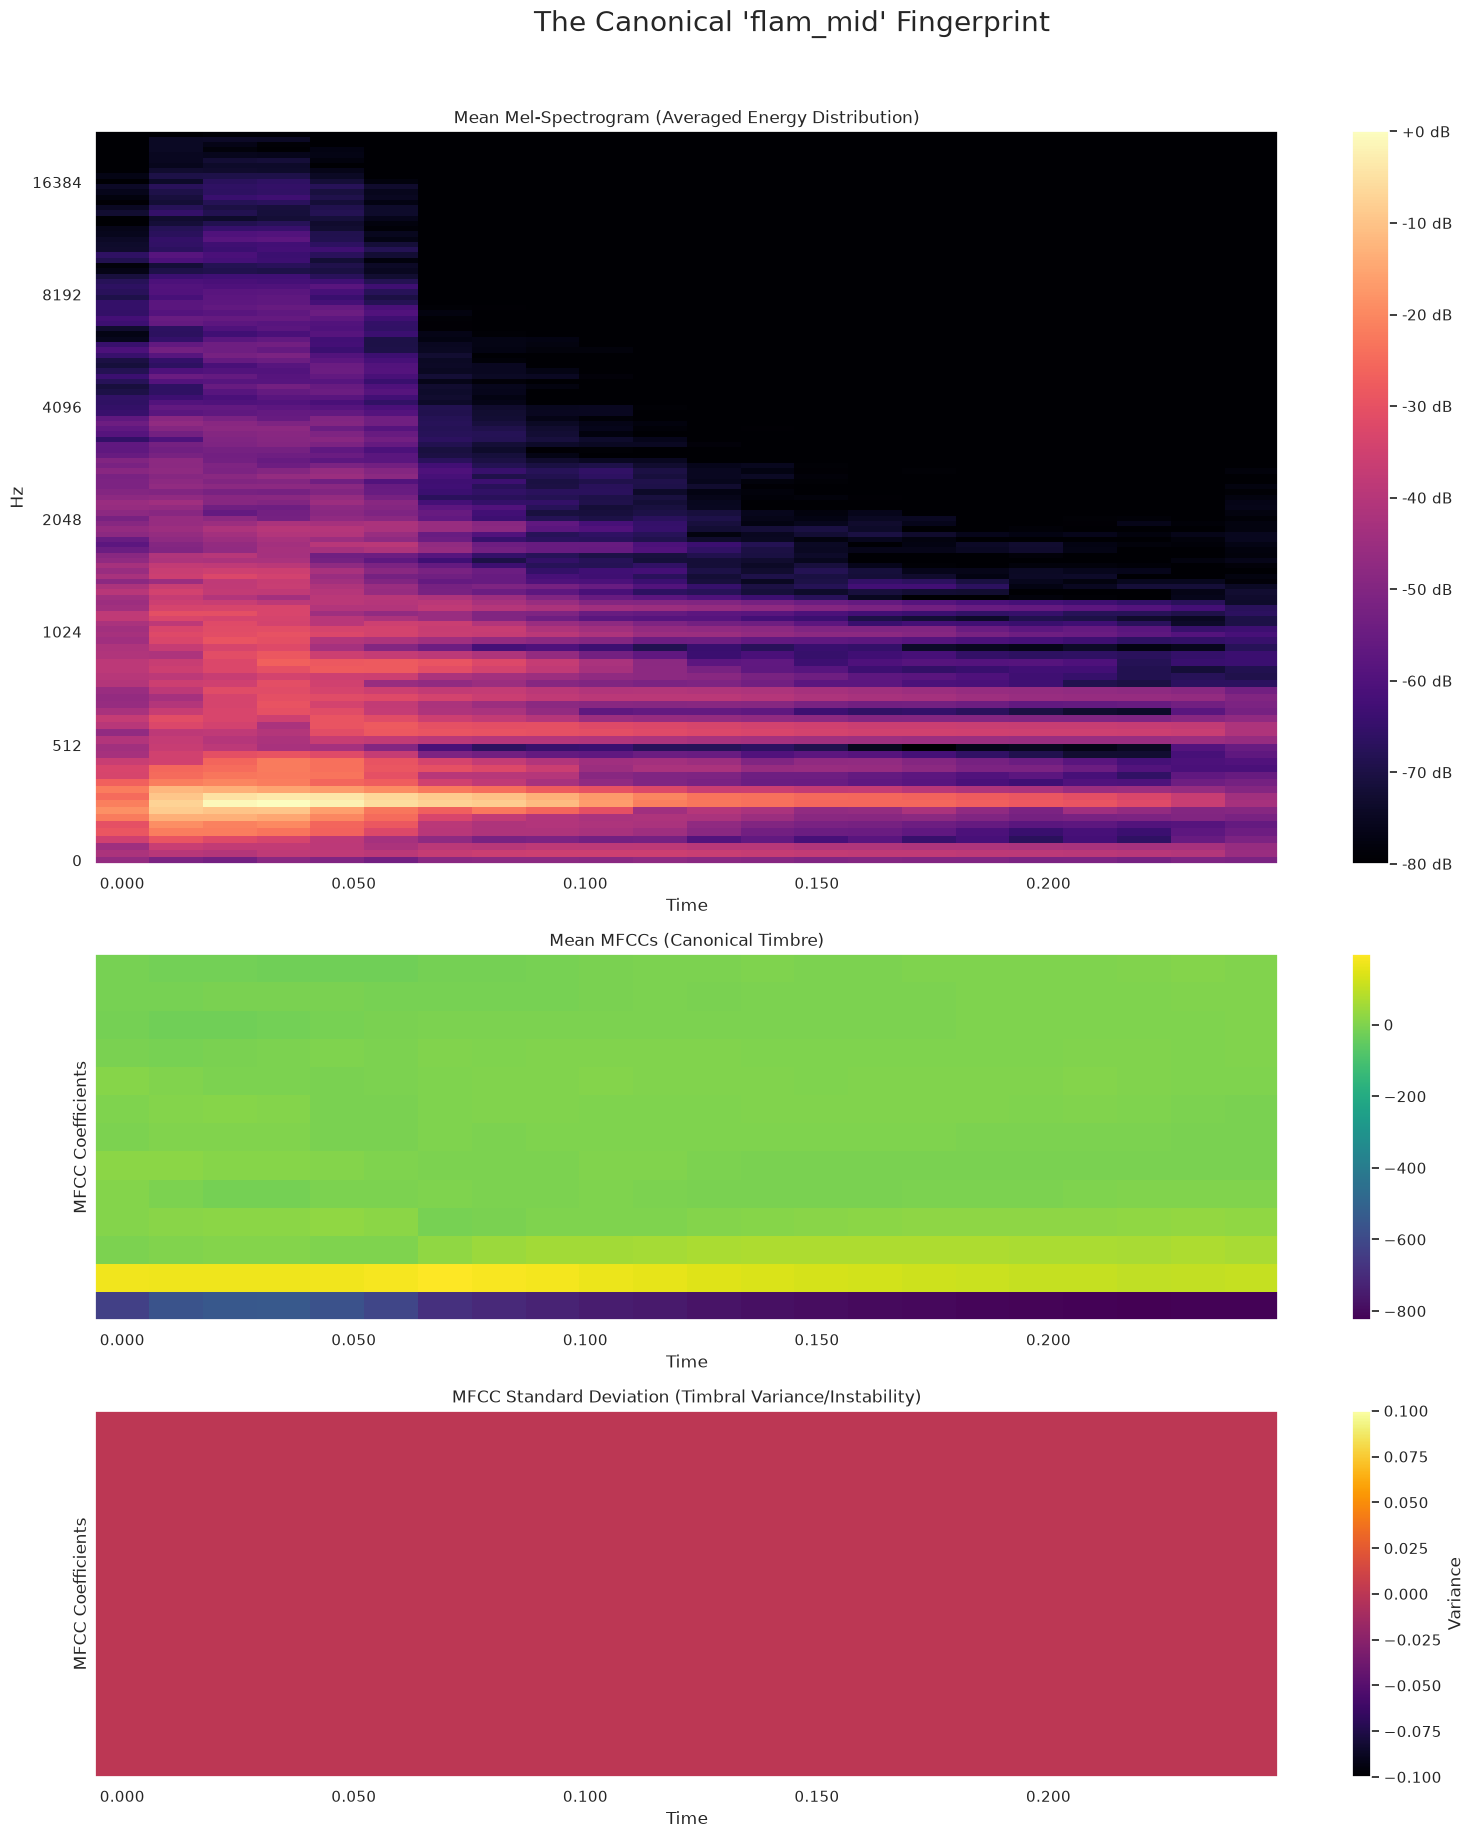

In [10]:
mean_mel = np.mean(aligned_mels, axis=0)
mean_mfcc = np.mean(aligned_mfccs, axis=0)
std_mfcc = np.std(aligned_mfccs, axis=0) # Shows where the timbre varies the most between hits

fig, axes = plt.subplots(3, 1, figsize=(16, 18), gridspec_kw={'height_ratios': [2, 1, 1]})
fig.suptitle(f"The Canonical '{TARGET_STROKE}' Fingerprint", fontsize=20, y=1.02)

# 1. Averaged Mel-Spectrogram
img1 = librosa.display.specshow(mean_mel, x_axis='time', y_axis='mel', sr=sr, ax=axes[0], cmap='magma')
axes[0].set_title("Mean Mel-Spectrogram (Averaged Energy Distribution)")
fig.colorbar(img1, ax=axes[0], format="%+2.0f dB")

# 2. Mean MFCCs (Timbre)
img2 = librosa.display.specshow(mean_mfcc, x_axis='time', sr=sr, ax=axes[1], cmap='viridis')
axes[1].set_title("Mean MFCCs (Canonical Timbre)")
axes[1].set_ylabel("MFCC Coefficients")
fig.colorbar(img2, ax=axes[1])

# 3. MFCC Variance (Timbral Stability)
# Bright yellow spots mean the player strikes it differently every time. Dark purple means extreme consistency.
img3 = librosa.display.specshow(std_mfcc, x_axis='time', sr=sr, ax=axes[2], cmap='inferno')
axes[2].set_title("MFCC Standard Deviation (Timbral Variance/Instability)")
axes[2].set_ylabel("MFCC Coefficients")
fig.colorbar(img3, ax=axes[2], label="Variance")

plt.tight_layout()
plt.show()

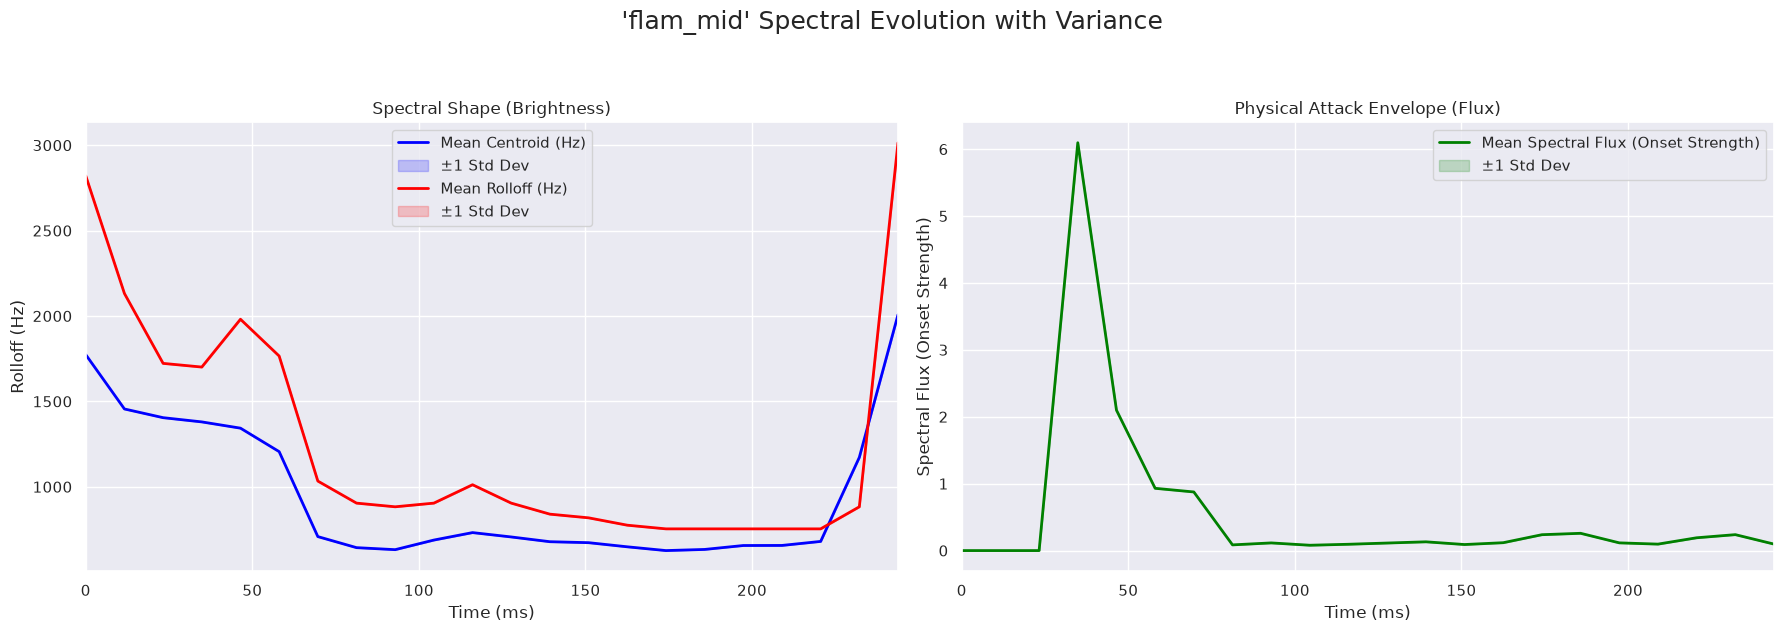

In [11]:
t_axis = librosa.frames_to_time(range(median_frames), sr=sr) * 1000 # in ms

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle(f"'{TARGET_STROKE}' Spectral Evolution with Variance", fontsize=18, y=1.05)

def plot_trajectory(ax, aligned_data, label, color):
    mean_val = np.mean(aligned_data, axis=0)
    std_val = np.std(aligned_data, axis=0)
    ax.plot(t_axis, mean_val, color=color, linewidth=2, label=f"Mean {label}")
    ax.fill_between(t_axis, np.maximum(0, mean_val - std_val), mean_val + std_val, color=color, alpha=0.2, label="±1 Std Dev")
    ax.set_xlabel("Time (ms)")
    ax.set_ylabel(label)
    ax.legend()
    ax.set_xlim(0, max(t_axis))

# Centroid & Rolloff
plot_trajectory(axes[0], aligned_cent, "Centroid (Hz)", "blue")
plot_trajectory(axes[0], aligned_rolloff, "Rolloff (Hz)", "red")
axes[0].set_title("Spectral Shape (Brightness)")

# Spectral Flux (Attack Envelope)
plot_trajectory(axes[1], aligned_flux, "Spectral Flux (Onset Strength)", "green")
axes[1].set_title("Physical Attack Envelope (Flux)")

plt.tight_layout()
plt.show()

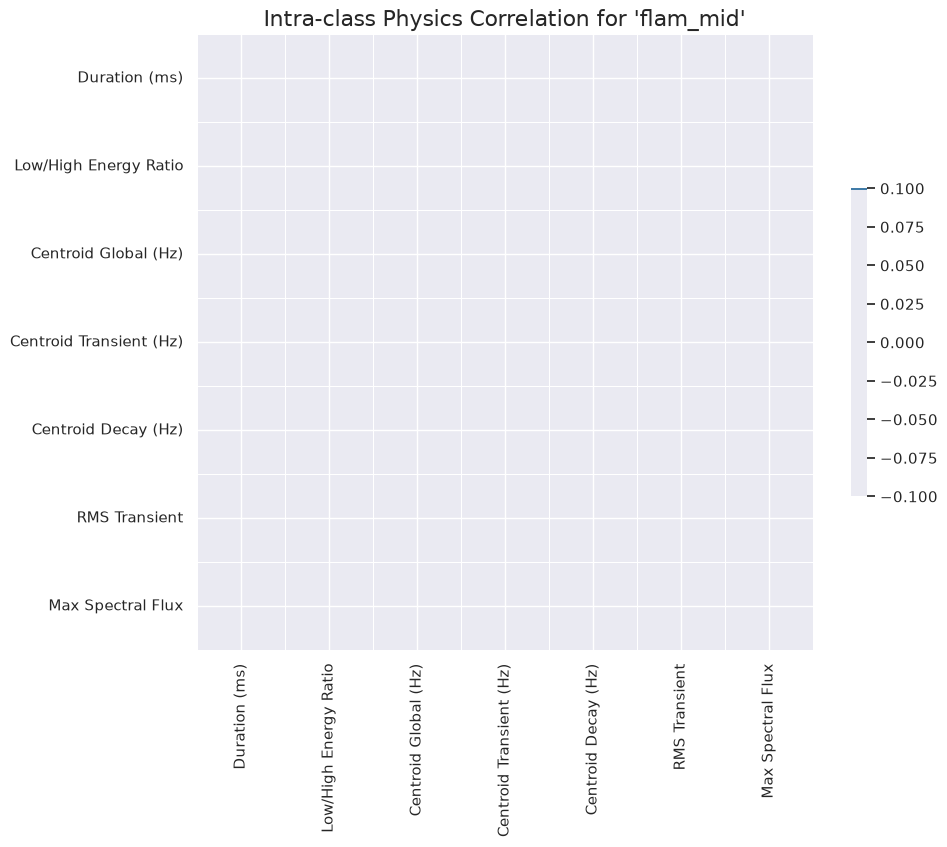

In [13]:
plt.figure(figsize=(10, 8))
plt.title(f"Intra-class Physics Correlation for '{TARGET_STROKE}'", fontsize=16)

# Drop file name, compute correlation
intra_corr = df.drop(columns=["File"]).corr(method="pearson")

# Mask upper triangle
mask = np.triu(np.ones_like(intra_corr, dtype=bool))
cmap = sns.diverging_palette(10, 240, as_cmap=True)

sns.heatmap(intra_corr, mask=mask, cmap=cmap, vmax=.8, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .5}, annot=True, fmt=".2f")
plt.show()

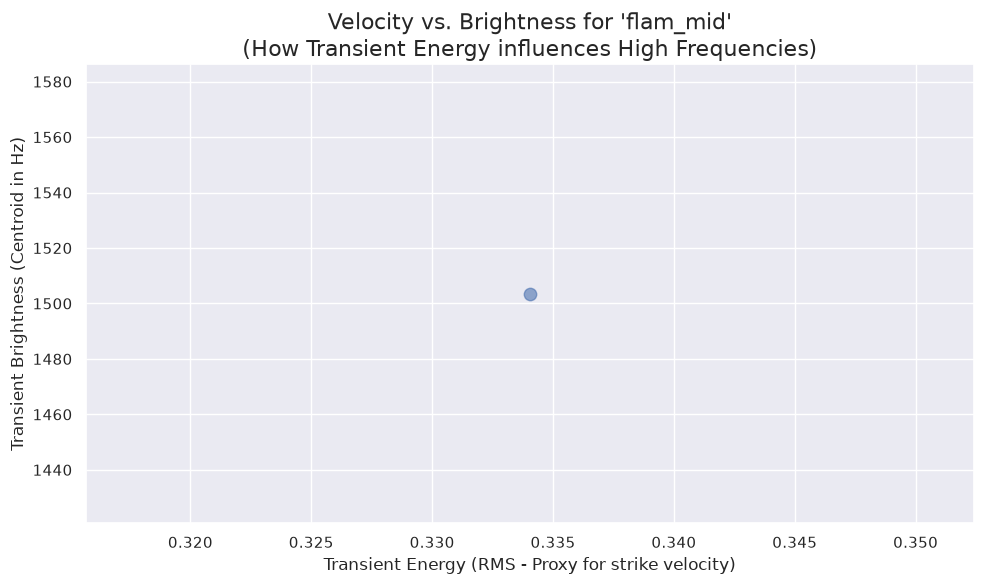

In [14]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.regplot(data=df, x="RMS Transient", y="Centroid Transient (Hz)", 
            scatter_kws={"alpha":0.6, "s":80}, line_kws={"color":"red"}, ax=ax)

ax.set_title(f"Velocity vs. Brightness for '{TARGET_STROKE}'\n(How Transient Energy influences High Frequencies)", fontsize=16)
ax.set_xlabel("Transient Energy (RMS - Proxy for strike velocity)")
ax.set_ylabel("Transient Brightness (Centroid in Hz)")

plt.tight_layout()
plt.show()